
--- Summary Statistics (in Seconds) ---
       Static1_sec  Inter1_sec  Static2_sec  Inter2_sec
count        10.00       10.00        10.00       10.00
mean         59.70       51.70        50.70       36.00
std          39.01       28.49         6.18        4.88
min          19.00       21.00        42.00       29.00
25%          28.00       26.75        46.50       32.25
50%          51.00       45.00        50.00       35.50
75%          84.75       73.25        54.50       39.75
max         138.00       99.00        62.00       44.00


/tmp/ipykernel_2790/3544354700.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Task_Condition', y='Mean_Seconds', data=mean_times, palette='viridis')


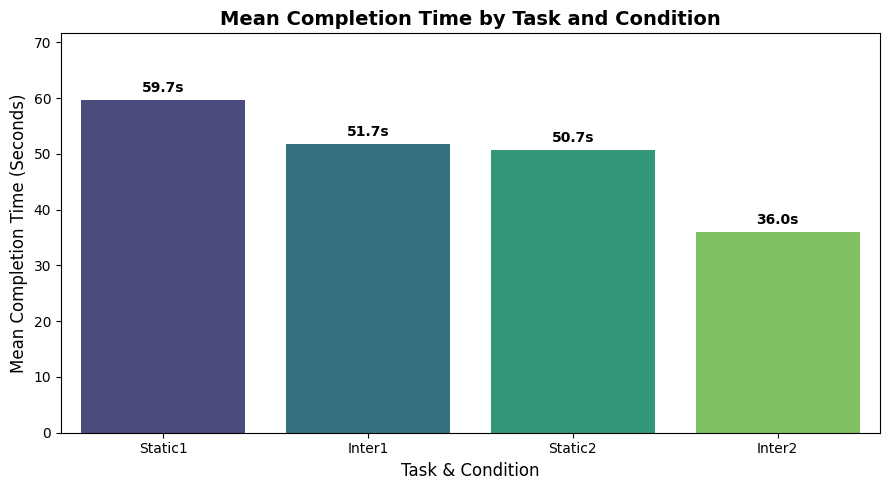

/tmp/ipykernel_2790/3544354700.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Condition', y='Accuracy (%)', data=acc_data, palette='Blues_d')


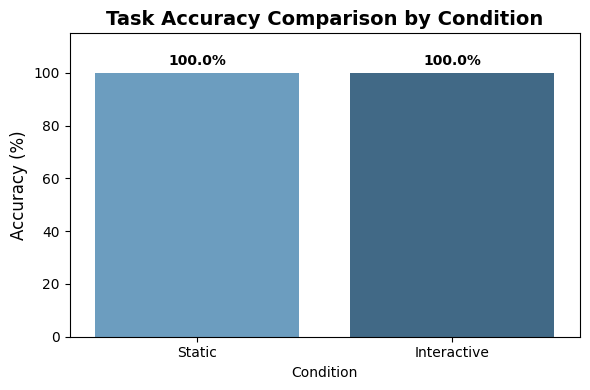

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('Survey_Data.csv')
df_clean = df.dropna(subset=['Tester']).copy()

def mmss_to_seconds(val):
    if pd.isna(val):
        return None
    parts = str(val).strip().split(':')
    if len(parts) == 2:
        try:
            return int(parts[0]) * 60 + int(parts[1])
        except ValueError:
            return None
    try:
        return float(val)
    except ValueError:
        return None

time_cols = ['Static1', 'Inter1', 'Static2', 'Inter2']
for col in time_cols:
    df_clean[col + '_sec'] = df_clean[col].apply(mmss_to_seconds)

sec_cols = [col + '_sec' for col in time_cols]

# Descriptive statistics
print("\n--- Summary Statistics (in Seconds) ---")
print(df_clean[sec_cols].describe().round(2))

# Mean Completion Times
plt.figure(figsize=(9, 5))
mean_times = df_clean[sec_cols].mean().reset_index()
mean_times.columns = ['Task_Condition', 'Mean_Seconds']
mean_times['Task_Condition'] = mean_times['Task_Condition'].str.replace('_sec', '')

sns.barplot(x='Task_Condition', y='Mean_Seconds', data=mean_times, palette='viridis')
plt.title('Mean Completion Time by Task and Condition', fontsize=14, fontweight='bold')
plt.xlabel('Task & Condition', fontsize=12)
plt.ylabel('Mean Completion Time (Seconds)', fontsize=12)
plt.ylim(0, max(mean_times['Mean_Seconds']) * 1.2)

for index, row in mean_times.iterrows():
    plt.text(index, row['Mean_Seconds'] + 1.5, f"{row['Mean_Seconds']:.1f}s", color='black', ha="center", fontweight='bold')

plt.tight_layout()
plt.show()

# Accuracy Comparison
acc_data = pd.DataFrame({
    'Condition': ['Static', 'Interactive'],
    'Accuracy (%)': [100.0, 100.0]
})

plt.figure(figsize=(6, 4))
sns.barplot(x='Condition', y='Accuracy (%)', data=acc_data, palette='Blues_d')
plt.title('Task Accuracy Comparison by Condition', fontsize=14, fontweight='bold')
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(0, 115)

for index, row in acc_data.iterrows():
    plt.text(index, row['Accuracy (%)'] + 3, f"{row['Accuracy (%)']}%", color='black', ha="center", fontweight='bold')

plt.tight_layout()
plt.show()